---
---

<h1><center><ins>Exercise Sheet 5</ins></center></h1>
<h2><center>Numerical Methods <br>

---
---

In [196]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from numpy import exp, cos

## Exercise 1 - Numerical derivative

**(A)** Compute the derivative of the following two functions:

$$ f_1(x) = x^2 + \cos(x) $$

$$ f_2(x) = \exp(x) - x^3 $$

in correspondence of at least $N = 50$ values $x_i$ ($i = 1, ..., N$) of the variable $x$ in the interval $[1,5]$. To do this, *write your own code to compute the derivatives numerically*.

**(B)** Compare the resulting values you get for the numerical derivatives with the corresponding analytic solutions. Calculate the value of the quantity $q$ for each function:

$$ q = \sum_{i=1}^N \frac{\left[d_i - f'(x_i) \right]}{f'(x_i)} $$

where $d_i$ are the values you obtained for the numerical derivatives for each of the $N$ abscissas, and $f'(x_i)$ are the analytical derivatives evaluated in points $x_i$. How does the value of $q$ change when changing the value of $h$ to compute the derivatives numerically? How do the values of $q$ compare for the two functions? Discuss your findings.

q for f1: 0.0001411959690491907
q for f2: 0.0003658436771951408
h = 1e-01   q1 =  1.423e+00   q2 =  3.713e+00
h = 1e-02   q1 =  1.413e-01   q2 =  3.664e-01
h = 1e-03   q1 =  1.412e-02   q2 =  3.659e-02
h = 1e-04   q1 =  1.412e-03   q2 =  3.658e-03
h = 1e-05   q1 =  1.412e-04   q2 =  3.658e-04
h = 1e-06   q1 =  1.412e-05   q2 =  3.659e-05
h = 1e-07   q1 =  1.439e-06   q2 =  3.697e-06
h = 1e-08   q1 =  1.652e-07   q2 =  7.801e-07
h = 1e-09   q1 =  6.497e-06   q2 =  1.252e-05
h = 1e-10   q1 =  2.222e-05   q2 =  4.531e-05
h = 1e-11   q1 =  1.263e-04   q2 = -1.448e-03
h = 1e-12   q1 =  6.713e-03   q2 =  1.906e-03
h = 1e-13   q1 =  2.816e-02   q2 = -4.594e-03
h = 1e-14   q1 =  2.876e-01   q2 = -2.213e-01
h = 1e-15   q1 = -7.807e-01   q2 =  3.937e+00


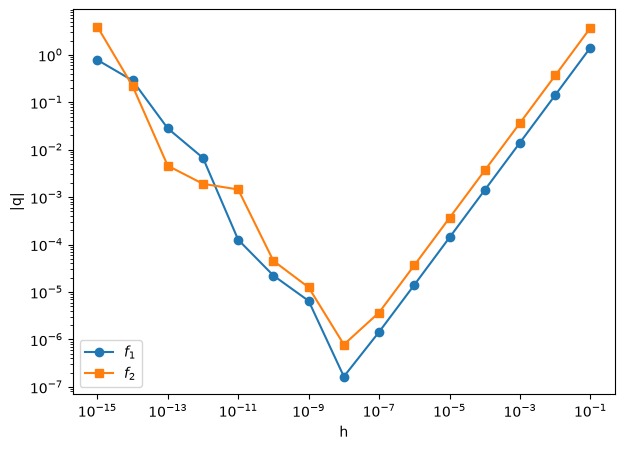

In [197]:
# q = np.sum
# wenn h größer, was macht q ? 

# (A):

def f1(x):
    return x**2 + cos(x)

def f2(x):
    return exp(x) - x**3

def f1_derivative(x):
    return 2*x - np.sin(x)

def f2_derivative(x):
    return exp(x) - (3 * x**2)

def ableitung(f, h, x):
    return (f(x+h) - f(x))/ h

x = np.linspace(1, 5, 50)
    # linspace ... wie viele Werte dazwischen
    # arange ... welche step size zB in fünfer Schritten

def q_value(f, f_derivative, h, x): 
    # compares each numerical derivative d with the exact value 
    d = ableitung(f, h, x)
    exact = f_derivative(x) # exact derivatives 
    return np.sum((d - exact)/ exact) # sums the relative derivations 

h = 1e-5
print(f'q for f1: {q_value(f1, f1_derivative, h, x)}')
print(f'q for f2: {q_value(f2, f2_derivative, h, x)}')

# (B):

h_values = 10.0**np.arange(-1, -16, -1) # how q changes with h, h = 1e-1 to 1e-15 in steps of (-1), 10.0 raises the values in the parenthesis! float needed 
q1 = []
q2 = []
for h in h_values:
    q1.append(q_value(f1, f1_derivative, h, x))
    q2.append(q_value(f2, f2_derivative, h, x))
    print(f'h = {h:.0e}   q1 = {q1[-1]: .3e}   q2 = {q2[-1]: .3e}') 
        #[-1] is the last entry, the one that was just added
        # .0e means 0 digits after decimal point
        # .3e means 3 digits after decimal point


# From AI: 
plt.figure(figsize=(7, 5))
plt.loglog(h_values, np.abs(q1), 'o-', label='$f_1$')
plt.loglog(h_values, np.abs(q2), 's-', label='$f_2$')
plt.xlabel('h')
plt.ylabel('|q|')
plt.legend()
plt.show()


f2 has larger second derivatives as e**x grows quickly, this means that the truncation error and therefore q is genereally larger than for f1

## Exercise 2 - Newton-Cotes formulas

In the file ```surface_luminosity.txt``` you will find the numerical function describing the surface luminosity $\Sigma$ of a globular star cluster as a function of the distance $R$ from its centre (projected on the plane of the sky). Compute the total luminosity $L$ of the system by performing the integral

$$ L = \int_0^{R_{\text{max}}} \Sigma(R) \, 2 \pi R \, dR $$

using the trapezoid rule and Simpson's rule, and compare the results you obtain. To do this, first choose one of these methods and implement **your own algorithm to compute the integral with it**; for the other method, use the corresponding built-in python function ```scipy.integrate.trapz``` or ```scipy.integrate.simps``` and familiarize on its usage.

In [198]:
# haben keine Funktion, sondern Datenpunkte 
# linerare Interpolation ! 
# Trapezoid rule 
# Aufsummieren aller Trapeze 
# result should be L = 1,2 * 10^6 

data = np.loadtxt("surface_luminosity.txt")
R = data[:, 0] # first column (radius)
Sigma = data[:, 1] # second column (surface luminosity)

y = Sigma * 2 *np.pi * R

def trapezoid_method(x,y): # great to use here with uneven spacing (from tutorial class)
    integral = 0
    for i in range (len(x) -1):
        dx = x[i+1] - x[i]
        integral += 0.5 * dx * (y[i] + y[i+1])
    return integral 

def simpson_method(x, y): # required equal spacing, not good to use here (from tutorial class)
    if len(y) % 2 == 0:
        raise ValueError('number of points needs to be odd') 
        # Simpson definiert für gerade Zwischenräume -> ungerade Anzahl an Punkten! 

    integral = y[0]
    for i in range(1, len(y), 2):
        integral += 4*y[i] + 2*y[i+1]

    return (integral - y[-1])*(x[-1] - x[0]) / (3*len(y))

L_trapezoid = trapezoid_method(R, y)
L_trapezoid_scipy = scipy.integrate.trapezoid(y, x = R)
L_simpson = scipy.integrate.simpson(y, x = R) # makes sense to use built-in due to unequal spacing 

print(f'Number of points: {len(R)}')
print(f'Trapezoid method (own): {L_trapezoid}')
print(f'Trapezoid method (scipy): {L_trapezoid_scipy}')
print(f'Simpson method (scipy): {L_simpson}')
print(f'Relative difference between own Trapezoid and scipy Trapezoid: {abs(L_trapezoid - L_trapezoid_scipy) / L_trapezoid_scipy}')
print(f'Relative difference between own Trapezoid and Simpson: {abs(L_trapezoid - L_simpson) / L_simpson}')


Number of points: 69
Trapezoid method (own): 1285408.7095045173
Trapezoid method (scipy): 1285408.7095045173
Simpson method (scipy): 1282549.6319938095
Relative difference between own Trapezoid and scipy Trapezoid: 0.0
Relative difference between own Trapezoid and Simpson: 0.002229213934016067


<function matplotlib.pyplot.show(close=None, block=None)>

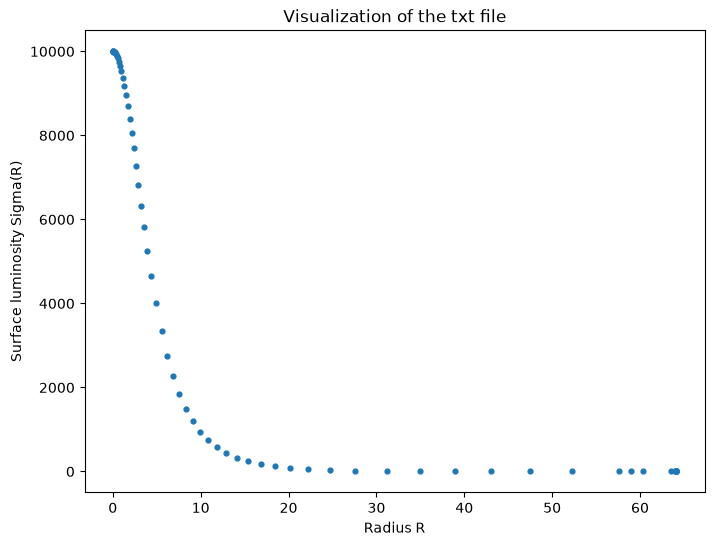

In [199]:
plt.figure(figsize=(8,6)) 

plt.title('Visualization of the txt file')
plt.xlabel('Radius R')
plt.ylabel('Surface luminosity Sigma(R)')

plt.scatter(R,Sigma, s = 12)
plt.show 

## Exercise 3 - Gaussian Quadrature

**(A)** Compute the following integral by using a 4-point Gaussian quadrature. 

$$ I = \int_{-1}^{1} \cos(x) dx $$

To do this, use the Legendre polynomial of degree 4:

$$ P_4(x) = \frac{1}{8}(35 x^4 - 30 x^2 +3) $$

At this link: https://en.wikipedia.org/wiki/Gauss%E2%80%93Legendre_quadrature you can find the roots of Legendre polynomials and the necessary weights to solve the integral (i.e., you do not have to calculate them all from scratch!).

**(B)** Compare the result with the ones you obtain when using a Legendre polynomial of degree 3, 2, and 1, and comment your findings.

In [200]:
# deuscthes Wiki ! 
# B : 3, 2, 1 Punkt auch Wikipedia 

# (A):

def cos_function(x):
    return cos(x)

# def legendre_p4(x):
    #return 1/8 * (35 * x**4 - 30 * x**2 +3)

# n = 4:
legendre_points_p4 = [-abs(np.sqrt(3/7 + 2/7 * np.sqrt(6/5))), -abs(np.sqrt(3/7 - 2/7 * np.sqrt(6/5))), abs(np.sqrt(3/7 - 2/7 * np.sqrt(6/5))), abs(np.sqrt(3/7 + 2/7 * np.sqrt(6/5)))]
legendre_weights_p4 = [(18 - np.sqrt(30))/36, (18 + np.sqrt(30))/36, (18 + np.sqrt(30))/36, (18 - np.sqrt(30))/36]

integral_with_p4 = 0
for i in range(4):
    integral_with_p4 += legendre_weights_p4[i] * cos_function(legendre_points_p4[i])

print(f'The integral of the function using the legendre polynomial of degree 4 is {integral_with_p4}')

# (B):

# n = 3:
legendre_points_p3 = [-abs(np.sqrt(3/5)), 0, abs(np.sqrt(3/5))]
legendre_weights_p3 = [5/9, 8/9, 5/9]

integral_with_p3 = 0
for i in range(3):
    integral_with_p3 += legendre_weights_p3[i] * cos_function(legendre_points_p3[i])

print(f'The integral of the function using the legendre polynomial of degree 3 is {integral_with_p3}')

# n = 2:
legendre_points_2 = [-abs(np.sqrt(1/3)), abs(np.sqrt(1/3))]
legendre_weights_2 = [1,1]

integral_with_p2 = 0
for i in range(2):
    integral_with_p2 += legendre_weights_2[i] * cos_function(legendre_points_2[i])

print(f'The integral of the function using the legendre polynomial of degree 2 is {integral_with_p2}')


# n = 1:
legendre_points_1 = [0]
legendre_weights_1 = [2]

integral_with_p1 = 0
for i in range(1):
    integral_with_p1 += legendre_weights_1[i] * cos_function(legendre_points_1[i])

print(f'The integral of the function using the legendre polynomial of degree 1 is {integral_with_p1}')

The integral of the function using the legendre polynomial of degree 4 is 1.6829416886959736
The integral of the function using the legendre polynomial of degree 3 is 1.683003547726917
The integral of the function using the legendre polynomial of degree 2 is 1.6758236553899863
The integral of the function using the legendre polynomial of degree 1 is 2.0


The more degrees we use, the more specific the solution will become, using degree 1 is giving us a number quite far away from the actual solution. 

## Exercise 4 - Monte Carlo integration 

Consider the following integral:
$$ I = \int_0^1 \cos \left(\frac{\pi x}{2} \right) dx = \frac{2}{\pi} $$

**(A)** Compute the above integral and its variance by using the following Monte Carlo methods:

1. mean value

How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.



I = 0.6352897256061829
true value = 0.6366197723675814
difference = -0.0013300467613984734
variance = 9.426444214884446e-06
sigma_I = 0.003070251490494622
N =       10   I = 0.76305   sigma_I = 6.29e-02
N =      100   I = 0.59786   sigma_I = 3.18e-02
N =     1000   I = 0.64173   sigma_I = 9.68e-03
N =    10000   I = 0.63385   sigma_I = 3.08e-03
N =   100000   I = 0.63895   sigma_I = 9.71e-04
N =  1000000   I = 0.63647   sigma_I = 3.08e-04


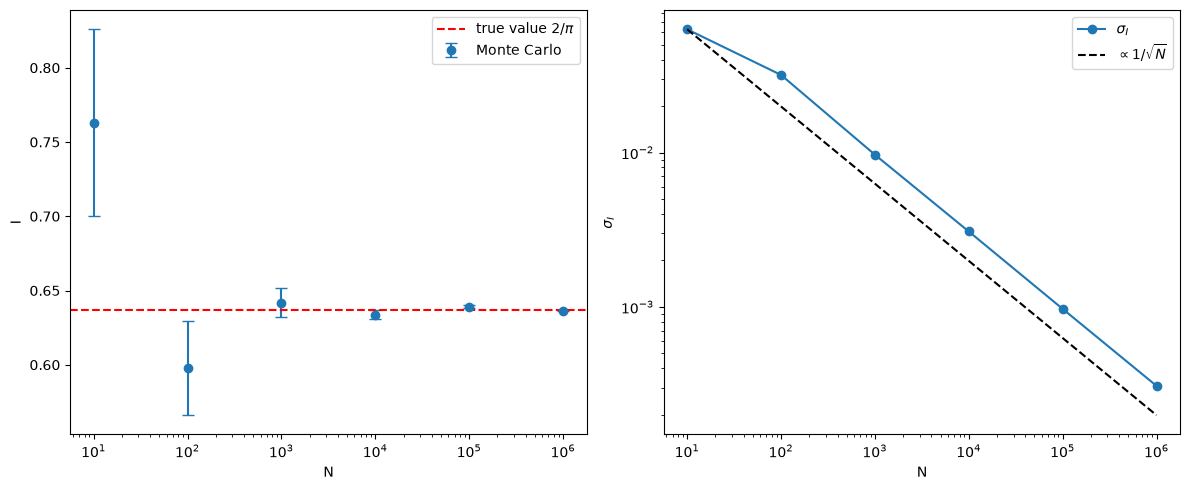

In [ ]:
# linspace 0 bis 1 ist unser randomly generated liste über die wir generieren
# mean value berechnen 
# sum(function(x_values[i]))
# print(sum)

# check: np.var(function)

# (A):

def function(x):
    return np.cos(np.pi * x / 2)

a = 0
b = 1
I_true = 2 / np.pi

def monte_carlo_mean(f, a, b, N):
    x = np.random.uniform(a, b, N) # N random points in [a, b]
    fx = f(x) # function values at those points
    I = (b - a) * np.mean(fx) # integral estimate
    var_I = (b - a)**2 * np.var(fx) / N # variance of the estimate
    return I, var_I

I, var_I = monte_carlo_mean(function, a, b, 10000)
print(f'I = {I}')
print(f'true value = {I_true}')
print(f'difference = {I - I_true}')
print(f'variance = {var_I}')
print(f'sigma_I = {np.sqrt(var_I)}')

# (B):
N_values = [10, 100, 1000, 10000, 100000, 1000000]
I_list = []
var_list = []

for N in N_values:
    I, var_I = monte_carlo_mean(function, a, b, N)
    I_list.append(I)
    var_list.append(var_I)
    print(f'N = {N:8d}   I = {I:.5f}   sigma_I = {np.sqrt(var_I):.2e}')

I_list = np.array(I_list)
sigma_list = np.sqrt(np.array(var_list))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


# With help of AI:
axes[0].errorbar(N_values, I_list, yerr=sigma_list, fmt='o', capsize=4, label='Monte Carlo')
axes[0].axhline(I_true, color='red', ls='--', label=r'true value $2/\pi$')
axes[0].set_xscale('log')
axes[0].set_xlabel('N')
axes[0].set_ylabel('I')
axes[0].legend()

axes[1].loglog(N_values, sigma_list, 'o-', label=r'$\sigma_I$')
axes[1].loglog(N_values, sigma_list[0] * np.sqrt(N_values[0] / np.array(N_values)),
               'k--', label=r'$\propto 1/\sqrt{N}$')
axes[1].set_xlabel('N')
axes[1].set_ylabel(r'$\sigma_I$')
axes[1].legend()

plt.tight_layout()
plt.show()


## Exercise 5 - Monte Carlo integration continued (optional)

**(A)** Compute the above integral from Exercise 4 and its variance by using the other Monte Carlo methods covered in the lecture:

2. Importance sampling

Hint: for importance sampling, you can use the following weight function: 
$$w(x) = A \frac{1}{1+\left( \pi x/2 \right)^2}$$
where you can determine the normalization constant by imposing:
$$\int_0^1 w(x) dx = 1 = A \frac{2}{\pi} \arctan(\pi/2) \rightarrow A = \frac{\pi}{2 \arctan(\pi/2)}$$


How do your results compare with the true value of the integral?

**(B)** Plot the behaviour of $I$ and of the variance $\sigma_{I}$ as a function of the number $N$ of points you generate for each of the methods. Consider at least 3 different values of $N$.

In [202]:
# Varianz berechnen 
# probabitliy distribution function basteln 
# umformen 